In [1]:
#imports 
from xgboost import XGBClassifier
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, RandomizedSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix)


In [2]:
df_undersampled_clean = pd.read_csv("/home/desktop/Optimizing-P2P-Loan-Thresholds-for-Borrowers-Using-LendingClub-Data-/dataset/clean_undersampled.csv", low_memory=False)

In [3]:
#MACHINE LEARNIGN TIME!!
y = df_undersampled_clean['profitable']
X = df_undersampled_clean.drop(columns=['profitable'])

In [4]:
# spliting the test set and the training set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

In [5]:
# splitting the training portion into train and validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1765, random_state = 42, stratify=y_train)

In [6]:
#Now we have an 80/15/15 split with our data
print(len(X_train), len(X_val), len(X_test))
print(y_train.mean(), y_val.mean(), y_test.mean())  # all should be ~0.5

384407 82390 82377
0.5000013007047218 0.5 0.499993930344635


In [11]:
#Now lets train with some hyper parameter tuning!!

param_grid = {
    'n_estimators': [2000], #number of trees 
    'learning_rate': [0.01, 0.1, 0.2, 0.05], #The step size for each new tree
    'max_depth': [3, 6, 9], #how deep each individual tree can grow. A depth-4 tree can make up to 4 sequential splits
    'early_stopping_rounds': [50], # stop training if validation performance doesn't improve for 50 consecutive rounds
    'min_child_weight': [1, 3, 5, 10], # minumum sum of instance weights
    'subsample': [0.6, 0.7, 0.8, 1.0], #What fraction fo rows each tree sees
    'reg_alpha': [0, 0.01, 0.1, 1, 10, 100], # Sets the strength of the L1 regularization. Adds the value of each coeffiecint as a penalty tterm to the loss function. AUto matic feature selection.
    'reg_lambda': [0.5, 0.7, 1, 1.3] # Sets the strength of the L2 regularization. Adds the sum of squares of the coeffiecient as a penalty to the loss fucntoin. imporantant when all features are imporatnnt or correlated and shoudl afect the model equally. 
}


In [12]:
xgb_model = XGBClassifier(random_state = 42, early_stopping_rounds = 50, eval_metric = 'logloss')

#use cross validation to determine wich sets are best.
grid_search = RandomizedSearchCV(xgb_model, param_grid, cv=5, scoring="roc_auc", n_iter = 130, n_jobs = -1, verbose = 2, random_state = 42)
grid_search.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=200)

best_xgb = grid_search.best_estimator_

#Best Params from tuning
print("Best Pramters: ", grid_search.best_params_)
print("Best Accuracy: ", grid_search.best_score_)

Fitting 10 folds for each of 100 candidates, totalling 1000 fits
[0]	validation_0-logloss:0.68205
[0]	validation_0-logloss:0.68205
[0]	validation_0-logloss:0.68202
[0]	validation_0-logloss:0.68206
[0]	validation_0-logloss:0.68210
[0]	validation_0-logloss:0.68561
[0]	validation_0-logloss:0.68204
[0]	validation_0-logloss:0.68178
[0]	validation_0-logloss:0.68206
[0]	validation_0-logloss:0.68564
[0]	validation_0-logloss:0.68210
[0]	validation_0-logloss:0.68563
[0]	validation_0-logloss:0.68565
[0]	validation_0-logloss:0.68565
[0]	validation_0-logloss:0.68559
[0]	validation_0-logloss:0.68209
[200]	validation_0-logloss:0.59792
[200]	validation_0-logloss:0.59793
[200]	validation_0-logloss:0.59768
[200]	validation_0-logloss:0.59802
[200]	validation_0-logloss:0.59776
[200]	validation_0-logloss:0.59777
[200]	validation_0-logloss:0.59766
[200]	validation_0-logloss:0.59766
[200]	validation_0-logloss:0.59800
[200]	validation_0-logloss:0.59783
[200]	validation_0-logloss:0.59403
[200]	validation_0-log

In [24]:
#Now using the best model on our validation set
y_pred = best_xgb.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

#test set accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:   ", recall_score(y_test, y_pred))
print("F1:       ", f1_score(y_test, y_pred))
print("ROC AUC:  ", roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:, 1]))
print()
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6803962271022251
Precision: 0.6847064087903346
Recall:    0.668714188598621
F1:        0.6766158154617142
ROC AUC:   0.7465263675560936

              precision    recall  f1-score   support

           0       0.68      0.69      0.68     41189
           1       0.68      0.67      0.68     41188

    accuracy                           0.68     82377
   macro avg       0.68      0.68      0.68     82377
weighted avg       0.68      0.68      0.68     82377

[[28506 12683]
 [13645 27543]]


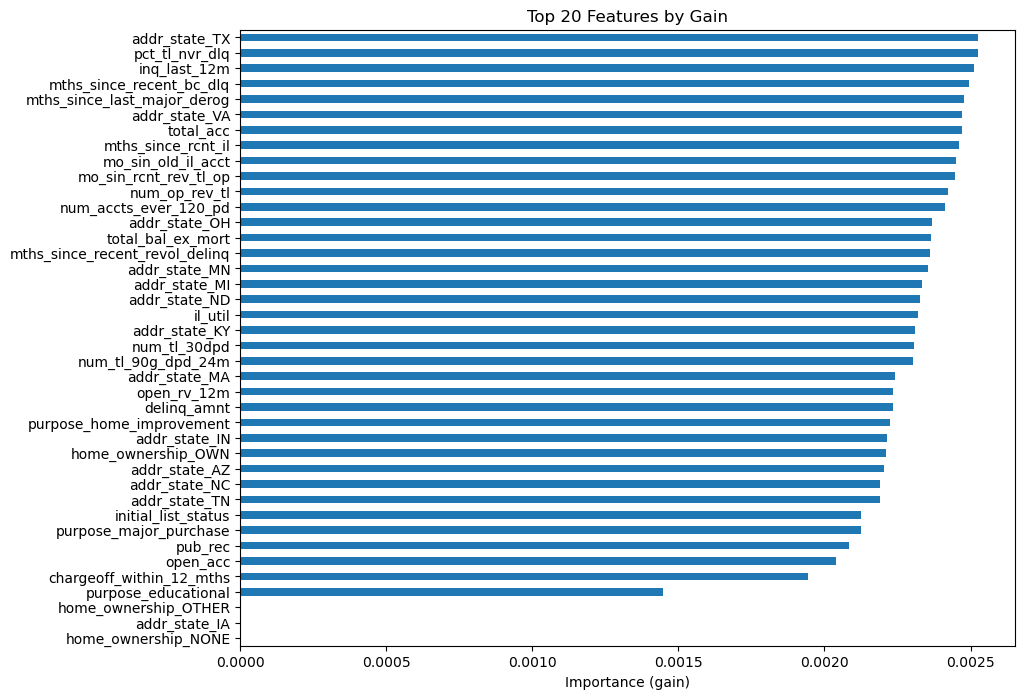

In [22]:
fi = pd.Series(best_xgb.feature_importances_, index=X.columns)
fi.sort_values(ascending=True).head(40).plot(kind='barh', figsize=(10, 8))
plt.title('Top 20 Features by Gain')
plt.xlabel('Importance (gain)')
plt.gca()#.invert_yaxis()
plt.show()

In [25]:
y_train_pred = best_xgb.predict(X_train)
print("Train accuracy:", accuracy_score(y_train, y_train_pred))
print("Test accuracy: ", accuracy_score(y_test, y_pred))
print("Gap:           ", accuracy_score(y_train, y_train_pred) - accuracy_score(y_test, y_pred))

Train accuracy: 0.73865460306394
Test accuracy:  0.6803962271022251
Gap:            0.0582583759617149
